# 20. 기상 민감도 추정(Q1)

질문: 폭염·열대야·호우가 있는 날 어떤 지역·업종·시간대·연령층의 매출이 얼마나 변하는가.

방법: 지역×업종 시리즈마다 고정효과 회귀.
`log(매출) = 요일 고정효과 + 주(week) 고정효과 + 이벤트 더미(폭염일, 열대야, 영업시간 비 10mm+, 한파) + 비 전날·다음 날 + 특별일 통제 + 오차`

- 주 고정효과가 계절 추세, 소비쿠폰·상생페이백 같은 정책 효과를 흡수한다. 날씨 효과는 같은 주 안에서 이벤트일과 아닌 날의 차이로 식별된다. 추석 연휴(10/3~9)는 다른 공휴일보다 매출이 훨씬 낮아 따로 통제한다(그 주의 10/10 비 효과가 왜곡되는 것을 막는다).
- 강도 구간은 두 지역 모두 5일 이상 있는 구간만 쓴다(강남은 영업시간 20~40mm가 하루뿐이라 20mm 이상으로 합쳤다).
- 표준오차는 Newey-West(7일)로 자기상관을 보정한다. 매출이 0인 날은 결측으로 둔다.
- 업종군·지역 단위 값은 시리즈별 계수를 역분산 가중 평균(고정효과 메타분석)으로 합친다.
- 계수는 `exp(β)−1`로 %로 바꿔 읽는다.

출력: `outputs/tables/s_*.csv` (시리즈별·업종군별·시간대별·연령별·거주지별 민감도), 그림 `outputs/figures/s*.png`

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd()))
from common import (FIG, TAB, REGIONS, REGION_NAME, TIME_BANDS, TB_NAME, AGE_GROUPS, FACE_GROUPS, EVENTS, load)
from analysis import (RC, SURFACE, INK, INK2, MUTED, GRID, AXIS, WASH, REGION_COLOR, AGE_COLOR, EVENT_COLOR,
                      exclusion_days, deviation, contrast, fe_ols, pool, pct, finish)

FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
plt.rcParams.update(RC)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 60)

cal = load("calendar"); EXCL = exclusion_days(cal)
prof = load("industry_profile")
day = load("model_panel_day"); tb = load("model_panel_tb"); w = load("weather_daily"); wtb = load("weather_tb")
scope = day[day.in_scope == 1].copy()
scope.loc[scope.sales == 0, "y"] = np.nan  # 거래 없는 날은 결측

EV = ["heat_day", "tropical", "rain_biz10", "cold12"]
LAGS = ["rain_biz10_lag1", "rain_biz10_lead1", "heat_day_lag1"]
CTRL = ["is_holiday", "is_chuseok_block", "is_pre_long_off", "is_post_long_off", "is_sandwich", "is_special"]  # 소비쿠폰 마지막 주는 주 고정효과가 흡수
FE = ["dow", "week"]
EV_NAME = {"heat_day": "폭염일", "tropical": "열대야", "rain_biz10": "비 10mm+", "cold12": "한파(참고)",
           "rain_biz10_lag1": "비 다음 날", "rain_biz10_lead1": "비 전날", "heat_day_lag1": "폭염 다음 날"}
for c in EV + LAGS:
    scope[c] = scope["w_" + c]
GROUP_ORDER = FACE_GROUPS + [g for g in scope.group.unique() if g not in FACE_GROUPS]


def run_series(df, keys, xvars, ctrl=CTRL, fe=FE, y="y", cov="hac"):
    """keys로 묶은 시리즈마다 고정효과 회귀. 변동이 없는 변수는 그 시리즈에서 뺀다."""
    rows = []
    for key, g in df.groupby(keys):
        key = key if isinstance(key, tuple) else (key,)
        xs = [c for c in xvars if g[c].nunique() > 1]
        cs = [c for c in ctrl if g[c].nunique() > 1]
        if not xs or g[y].notna().sum() < 60:
            continue
        res, _ = fe_ols(g, y, xs + cs, fe, cov=cov)
        res = res.loc[xs].reset_index().rename(columns={"index": "var"})
        for k, v in zip(keys, key):
            res[k] = v
        res["n_event"] = [int(g.loc[g[y].notna(), c].sum()) for c in xs]
        rows.append(res)
    return pd.concat(rows, ignore_index=True)


def forest(ax, pooled, order, ev, legend=True):
    """업종군(y) × 지역(색) 포레스트 플롯."""
    for i, r in enumerate(REGIONS):
        x = pooled.xs(r, level="region").reindex(order) if r in pooled.index.get_level_values("region") else None
        if x is None:
            continue
        ypos = np.arange(len(order)) + (i - 0.5) * 0.3
        ax.errorbar(x.pct, ypos, xerr=np.vstack([x.pct - x.lo, x.hi - x.pct]), fmt="o", color=REGION_COLOR[r],
                    ecolor=REGION_COLOR[r], elinewidth=1.3, ms=5.5, mec=SURFACE, mew=1, label=REGION_NAME[r], alpha=0.95)
    ax.axvline(0, color=INK2, lw=1)
    ax.set_yticks(range(len(order)), order)
    ax.invert_yaxis()
    ax.set_title(EV_NAME.get(ev, ev))
    ax.grid(axis="y", visible=False)
    if legend:
        ax.legend(loc="lower left")
print(f"대상 시리즈 {scope.groupby(['region','industry']).ngroups}개")

대상 시리즈 141개


## 1. 시리즈(지역×업종)별 일 단위 회귀

In [2]:
sens = run_series(scope, ["region", "industry"], EV + LAGS)
sens = sens.merge(prof[["region", "industry", "group", "small_biz", "discretionary", "outdoor", "sales_day", "cnt_day"]], on=["region", "industry"])
sens["event"] = sens["var"].map(EV_NAME)
sens.to_csv(TAB / "s_day_series.csv", index=False, encoding="utf-8-sig")
wide = sens.pivot_table(index=["region", "group", "industry"], columns="var", values=["pct", "p", "n_event"])
wide.columns = [f"{a}_{b}" for a, b in wide.columns]
wide.to_csv(TAB / "s_day_series_wide.csv", encoding="utf-8-sig")
print("시리즈 수", sens.groupby(["region", "industry"]).ngroups, "/ 이벤트 수(지역별, 시리즈 평균)")
sens.groupby(["region", "var"]).n_event.mean().unstack("var")[EV + LAGS].round(0)

시리즈 수 141 / 이벤트 수(지역별, 시리즈 평균)


var,heat_day,tropical,rain_biz10,cold12,rain_biz10_lag1,rain_biz10_lead1,heat_day_lag1
region,,,,,,,
chuncheon,30.0,6.0,21.0,3.0,21.0,21.0,30.0
gangnam,25.0,45.0,17.0,NaN,17.0,17.0,25.0


유의하게(p<0.05) 매출이 줄어든 시리즈 수. 비 10mm+에서 가장 많고, 폭염은 지역·업종에 따라 갈린다.

In [3]:
sig = sens[(sens.p < 0.05)].assign(dir=lambda x: np.where(x.coef < 0, "감소", "증가"))
cnt = sig.groupby(["region", "var", "dir"]).size().unstack("dir", fill_value=0).reindex(pd.MultiIndex.from_product([REGIONS, EV]), fill_value=0)
cnt["전체 시리즈"] = sens.groupby(["region", "var"]).size().reindex(cnt.index)
cnt

dir                   감소  증가  전체 시리즈
gangnam   heat_day     4  12    77.0
          tropical     4   1    77.0
          rain_biz10  20   2    77.0
          cold12       0   0     NaN
chuncheon heat_day     2   8    64.0
          tropical     1   4    64.0
          rain_biz10  24   1    64.0
          cold12      17   4    64.0

## 2. 업종군 × 지역 민감도(역분산 가중 평균)

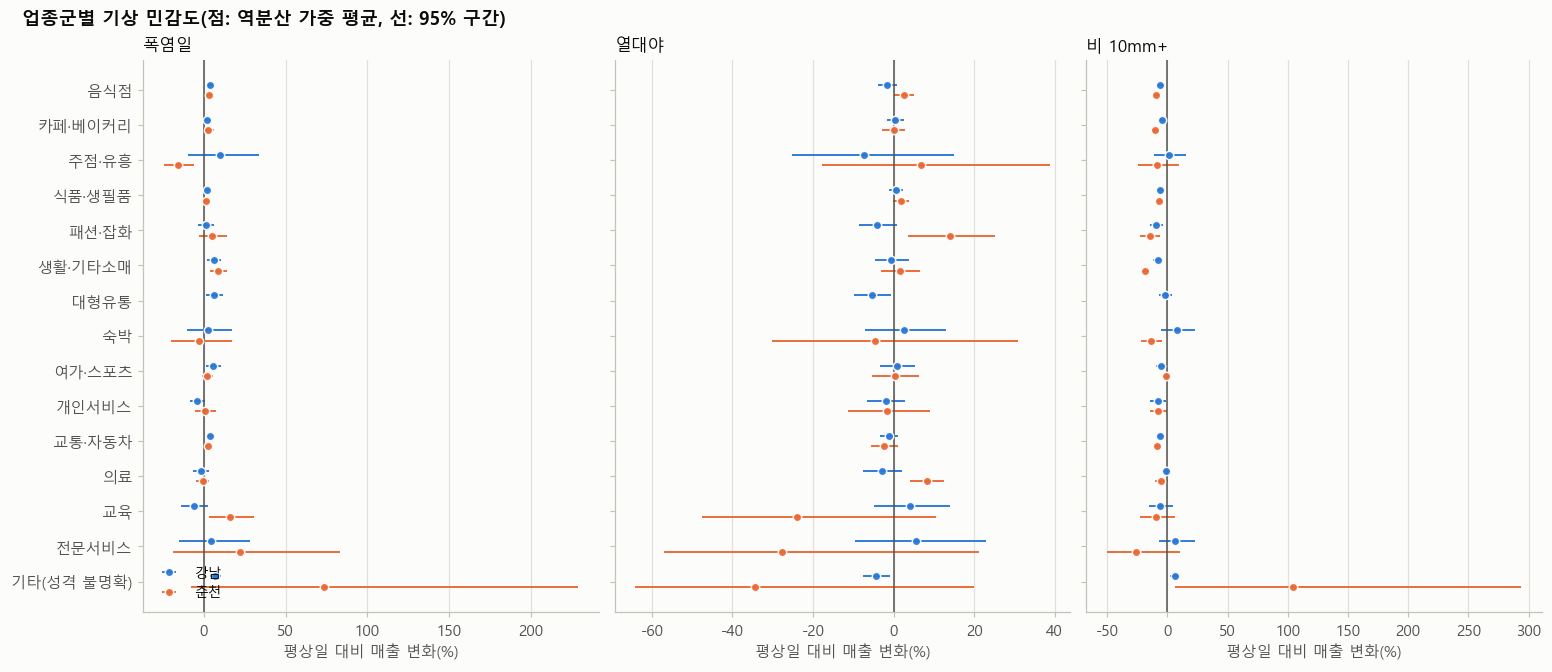

대면소비 전체(지역별):


pct   lo   hi   k
var              region                      
heat_day         chuncheon  2.7  1.6  3.8  48
                 gangnam    2.6  1.6  3.6  53
tropical         chuncheon  1.7  0.5  3.0  48
                 gangnam   -0.4 -1.5  0.6  53
rain_biz10       chuncheon -8.7 -9.8 -7.5  48
                 gangnam   -5.7 -6.9 -4.6  53
cold12           chuncheon -4.6 -5.7 -3.5  48
rain_biz10_lag1  chuncheon -0.6 -1.6  0.3  48
                 gangnam   -0.3 -1.1  0.5  53
rain_biz10_lead1 chuncheon -3.6 -4.7 -2.4  48
                 gangnam    0.4 -0.5  1.4  53
heat_day_lag1    chuncheon  2.1  1.0  3.2  48
                 gangnam    0.3 -0.4  1.0  53

In [4]:
pooled = {ev: pool(sens[sens["var"] == ev], ["region", "group"]) for ev in EV + LAGS}
P = pd.concat(pooled, names=["var", "region", "group"])
P.reset_index().assign(event=lambda x: x["var"].map(EV_NAME)).to_csv(TAB / "s_day_group.csv", index=False, encoding="utf-8-sig")
P_reg = pd.concat({ev: pool(sens[(sens["var"] == ev) & sens.group.isin(FACE_GROUPS)], ["region"]) for ev in EV + LAGS}, names=["var", "region"])
P_reg.reset_index().assign(event=lambda x: x["var"].map(EV_NAME)).to_csv(TAB / "s_day_region.csv", index=False, encoding="utf-8-sig")
fig, axes = plt.subplots(1, 3, figsize=(14, 6), sharey=True, layout="constrained")
for k, (ax, ev) in enumerate(zip(axes, ["heat_day", "tropical", "rain_biz10"])):
    forest(ax, pooled[ev], GROUP_ORDER, ev, legend=(k == 0))
    ax.set_xlabel("평상일 대비 매출 변화(%)")
finish(fig, FIG, "s01_forest_group", "업종군별 기상 민감도(점: 역분산 가중 평균, 선: 95% 구간)")
plt.show()
print("대면소비 전체(지역별):")
P_reg[["pct", "lo", "hi", "k"]].round(1)

## 3. 강도별 반응(dose-response)

더미 대신 구간 더미를 넣는다. 기준은 폭염은 일최고 31℃ 미만, 비는 영업시간 1mm 미만, 열대야는 밤 최저 23℃ 미만.

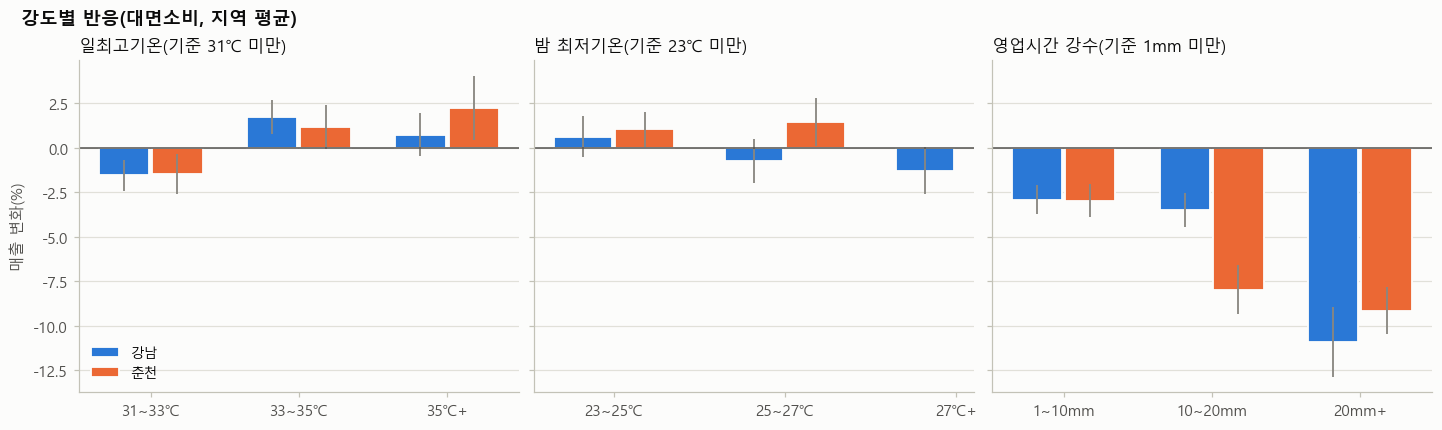

pct                lo                hi                 k        
region chuncheon gangnam chuncheon gangnam chuncheon gangnam chuncheon gangnam
var                                                                           
h31_33      -1.5    -1.6      -2.6    -2.4      -0.3    -0.7      48.0    53.0
h33_35       1.2     1.7      -0.0     0.8       2.4     2.7      48.0    53.0
h35p         2.2     0.7       0.5    -0.5       4.1     1.9      48.0    53.0
n23_25       1.0     0.6       0.1    -0.6       2.0     1.8      48.0    53.0
n25_27       1.5    -0.7       0.1    -2.0       2.8     0.5      48.0    53.0
n27p         NaN    -1.3       NaN    -2.6       NaN     0.1       NaN    53.0
r10_20      -8.0    -3.5      -9.3    -4.4      -6.6    -2.6      48.0    53.0
r1_10       -3.0    -2.9      -3.9    -3.7      -2.0    -2.1      48.0    53.0
r20p        -9.2   -10.9     -10.4   -12.9      -7.8    -8.9      48.0    53.0

In [5]:
d2 = scope.copy()
t, rb, nm = d2.w_ta_max_off, d2.w_rn_biz, d2.w_night_min
bins = {"h31_33": (t >= 31) & (t < 33), "h33_35": (t >= 33) & (t < 35), "h35p": t >= 35,
        "r1_10": (rb >= 1) & (rb < 10), "r10_20": (rb >= 10) & (rb < 20), "r20p": rb >= 20,
        "n23_25": (nm >= 23) & (nm < 25), "n25_27": (nm >= 25) & (nm < 27), "n27p": nm >= 27}
for k, v in bins.items():
    d2[k] = v.astype(int)
dose = run_series(d2[d2.group.isin(FACE_GROUPS)], ["region", "industry"], list(bins) + ["rain_biz10_lag1"])
dose_reg = pool(dose[dose["var"].isin(bins)], ["region", "var"])
dose_reg.reset_index().to_csv(TAB / "s_dose_region.csv", index=False, encoding="utf-8-sig")
BIN_NAME = {"h31_33": "31~33℃", "h33_35": "33~35℃", "h35p": "35℃+", "r1_10": "1~10mm", "r10_20": "10~20mm", "r20p": "20mm+",
            "n23_25": "23~25℃", "n25_27": "25~27℃", "n27p": "27℃+"}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True, layout="constrained")
for ax, (ttl, keys) in zip(axes, [("일최고기온(기준 31℃ 미만)", ["h31_33", "h33_35", "h35p"]),
                                   ("밤 최저기온(기준 23℃ 미만)", ["n23_25", "n25_27", "n27p"]),
                                   ("영업시간 강수(기준 1mm 미만)", ["r1_10", "r10_20", "r20p"])]):
    for i, r in enumerate(REGIONS):
        x = dose_reg.xs(r, level="region").reindex(keys)
        pos = np.arange(len(keys)) + (i - 0.5) * 0.36
        ax.bar(pos, x.pct, width=0.34, color=REGION_COLOR[r], label=REGION_NAME[r], edgecolor=SURFACE, linewidth=1.2)
        ax.errorbar(pos, x.pct, yerr=np.vstack([x.pct - x.lo, x.hi - x.pct]), fmt="none", ecolor=MUTED, elinewidth=1.2)
    ax.axhline(0, color=INK2, lw=1); ax.set_xticks(range(len(keys)), [BIN_NAME[k] for k in keys]); ax.set_title(ttl); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("매출 변화(%)"); axes[0].legend(loc="lower left")
finish(fig, FIG, "s02_dose", "강도별 반응(대면소비, 지역 평균)")
plt.show()
dose_reg[["pct", "lo", "hi", "k"]].round(1).unstack("region")

## 4. 시간대별 민감도

시간대 패널(지역×업종×일×시간대)에서 그 시간대의 비(1~5mm, 5mm+)와 더위(체감 33℃+)가 그 시간대 매출에 미치는 효과. 같은 통제·고정효과를 쓴다.

C:\Users\nk233\anaconda3\Lib\site-packages\statsmodels\regression\linear_model.py:1884: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(np.diag(self.cov_params()))


C:\Users\nk233\anaconda3\Lib\site-packages\statsmodels\regression\linear_model.py:1884: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(np.diag(self.cov_params()))


C:\Users\nk233\anaconda3\Lib\site-packages\statsmodels\regression\linear_model.py:1884: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(np.diag(self.cov_params()))


C:\Users\nk233\anaconda3\Lib\site-packages\statsmodels\regression\linear_model.py:1884: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(np.diag(self.cov_params()))
C:\Users\nk233\anaconda3\Lib\site-packages\statsmodels\regression\linear_model.py:1884: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(np.diag(self.cov_params()))


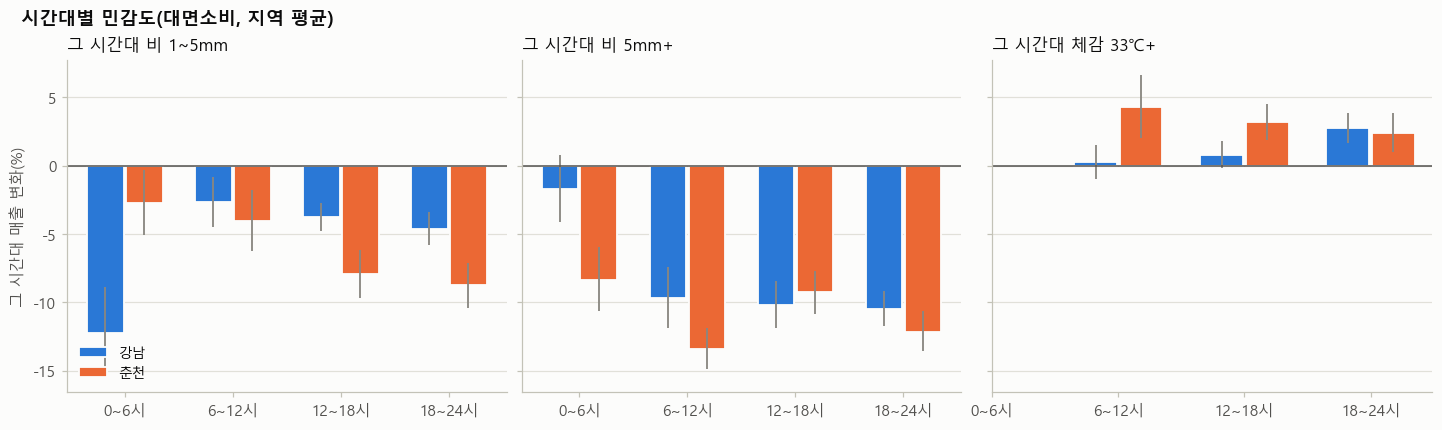

pct                      lo                      hi                  
tb                      00_05 06_11 12_17 18_23 00_05 06_11 12_17 18_23 00_05 06_11 12_17 18_23
var           region                                                                           
tb_r1_5       chuncheon  -2.8  -4.1  -7.9  -8.8  -5.1  -6.3  -9.7 -10.4  -0.4  -1.8  -6.2  -7.1
              gangnam   -12.2  -2.7  -3.7  -4.6 -15.5  -4.5  -4.8  -5.8  -8.9  -0.9  -2.7  -3.4
tb_r5p        chuncheon  -8.3 -13.4  -9.3 -12.1 -10.7 -14.9 -10.8 -13.6  -6.0 -11.9  -7.7 -10.7
              gangnam    -1.7  -9.7 -10.2 -10.5  -4.1 -11.9 -11.9 -11.7   0.8  -7.4  -8.4  -9.2
tb_heat       chuncheon   NaN   4.3   3.2   2.4   NaN   2.0   1.9   1.0   NaN   6.6   4.5   3.8
              gangnam     NaN   0.2   0.8   2.7   NaN  -1.0  -0.2   1.6   NaN   1.5   1.8   3.8
tropical_eve  chuncheon   NaN   NaN   NaN   2.0   NaN   NaN   NaN   0.9   NaN   NaN   NaN   3.0
              gangnam     NaN   NaN   NaN   0.1   NaN   NaN   NaN  -1.0   NaN   NaN   NaN   1.1
tropical_morn chuncheon   NaN   3.5   NaN   NaN   NaN   1.7   NaN   NaN   NaN   5.3   NaN   NaN
              gangnam     NaN  -0.7   NaN   NaN   NaN  -2.1   NaN   NaN   NaN   0.8   NaN   NaN

In [6]:
t2 = tb[(tb.in_scope == 1)].copy()
t2.loc[t2.sales == 0, "y"] = np.nan
t2["tb_r1_5"] = ((t2.wtb_rn_sum >= 1) & (t2.wtb_rn_sum < 5)).astype(int)
t2["tb_r5p"] = (t2.wtb_rn_sum >= 5).astype(int)
t2["tb_heat"] = t2.wtb_heat.astype(int)
t2["tropical_eve"] = (t2.w_tropical * (t2.tb == "18_23")).astype(int)
t2["tropical_morn"] = (t2.w_tropical_prev * (t2.tb == "06_11")).astype(int)
TBX = ["tb_r1_5", "tb_r5p", "tb_heat", "tropical_eve", "tropical_morn"]
sens_tb = run_series(t2, ["region", "industry", "tb"], TBX)
sens_tb = sens_tb.merge(prof[["region", "industry", "group", "small_biz"]], on=["region", "industry"])
sens_tb.to_csv(TAB / "s_tb_series.csv", index=False, encoding="utf-8-sig")
face_tb = sens_tb[sens_tb.group.isin(FACE_GROUPS)]
ptb = pd.concat({v: pool(face_tb[face_tb["var"] == v], ["region", "tb"]) for v in TBX}, names=["var", "region", "tb"])
ptb.reset_index().to_csv(TAB / "s_tb_region.csv", index=False, encoding="utf-8-sig")
ptb_g = pd.concat({v: pool(sens_tb[sens_tb["var"] == v], ["region", "group", "tb"]) for v in TBX}, names=["var", "region", "group", "tb"])
ptb_g.reset_index().to_csv(TAB / "s_tb_group.csv", index=False, encoding="utf-8-sig")
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True, layout="constrained")
for ax, (v, ttl) in zip(axes, [("tb_r1_5", "그 시간대 비 1~5mm"), ("tb_r5p", "그 시간대 비 5mm+"), ("tb_heat", "그 시간대 체감 33℃+")]):
    for i, r in enumerate(REGIONS):
        x = ptb.loc[v].xs(r, level="region").reindex(TIME_BANDS)
        pos = np.arange(4) + (i - 0.5) * 0.36
        ax.bar(pos, x.pct, width=0.34, color=REGION_COLOR[r], label=REGION_NAME[r], edgecolor=SURFACE, linewidth=1.2)
        ax.errorbar(pos, x.pct, yerr=np.vstack([x.pct - x.lo, x.hi - x.pct]), fmt="none", ecolor=MUTED, elinewidth=1.2)
    ax.axhline(0, color=INK2, lw=1); ax.set_xticks(range(4), [TB_NAME[t] for t in TIME_BANDS]); ax.set_title(ttl); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("그 시간대 매출 변화(%)"); axes[0].legend(loc="lower left")
finish(fig, FIG, "s03_timeband", "시간대별 민감도(대면소비, 지역 평균)")
plt.show()
ptb[["pct", "lo", "hi"]].round(1).unstack("tb")

## 5. 연령군별 민감도(회의 항목)

연령군(10-20대 / 30-50대 / 60대+)별 결제액을 지역×업종군 단위로 모아 같은 회귀를 돌린다.

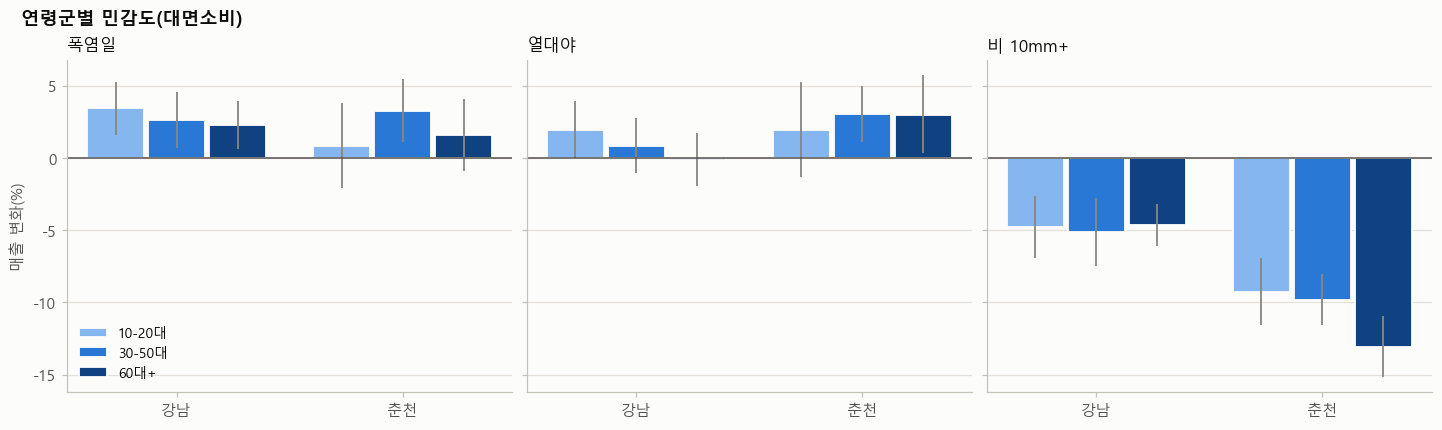

pct                  lo                  hi             
age_group            10-20대 30-50대  60대+ 10-20대 30-50대  60대+ 10-20대 30-50대  60대+
var        region                                                               
heat_day   chuncheon    0.8    3.3   1.6   -2.1    1.1  -0.9    3.8    5.5   4.1
           gangnam      3.4    2.6   2.3    1.6    0.7   0.6    5.3    4.5   4.0
tropical   chuncheon    1.9    3.0   3.0   -1.3    1.1   0.3    5.3    5.0   5.8
           gangnam      2.0    0.8  -0.1    0.0   -1.0  -1.9    3.9    2.7   1.7
rain_biz10 chuncheon   -9.3   -9.8 -13.1  -11.6  -11.6 -15.2   -6.9   -8.0 -10.9
           gangnam     -4.8   -5.1  -4.7   -6.9   -7.5  -6.1   -2.7   -2.8  -3.2

In [7]:
ag = load("card_day_age").merge(scope[["region", "industry", "group"]].drop_duplicates(), on=["region", "industry"])
ag = ag[ag.group.isin(FACE_GROUPS)].groupby(["region", "group", "age_group", "date"]).sales.sum().reset_index()
ag["y"] = np.log1p(ag.sales).where(ag.sales > 0)
ag = ag.merge(cal, on="date").merge(w[["region", "date"] + EV + LAGS], on=["region", "date"])
sens_age = run_series(ag, ["region", "group", "age_group"], EV + ["rain_biz10_lag1"])
sens_age.to_csv(TAB / "s_age_series.csv", index=False, encoding="utf-8-sig")
page = pd.concat({ev: pool(sens_age[sens_age["var"] == ev], ["region", "age_group"]) for ev in ["heat_day", "tropical", "rain_biz10"]}, names=["var", "region", "age_group"])
page.reset_index().to_csv(TAB / "s_age_region.csv", index=False, encoding="utf-8-sig")
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True, layout="constrained")
for ax, ev in zip(axes, ["heat_day", "tropical", "rain_biz10"]):
    for i, a in enumerate(AGE_GROUPS):
        x = page.loc[ev].xs(a, level="age_group").reindex(REGIONS)
        pos = np.arange(2) + (i - 1) * 0.27
        ax.bar(pos, x.pct, width=0.25, color=AGE_COLOR[a], label=a, edgecolor=SURFACE, linewidth=1.2)
        ax.errorbar(pos, x.pct, yerr=np.vstack([x.pct - x.lo, x.hi - x.pct]), fmt="none", ecolor=MUTED, elinewidth=1.2)
    ax.axhline(0, color=INK2, lw=1); ax.set_xticks(range(2), [REGION_NAME[r] for r in REGIONS]); ax.set_title(EV_NAME[ev]); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("매출 변화(%)"); axes[0].legend(loc="lower left")
finish(fig, FIG, "s04_age", "연령군별 민감도(대면소비)")
plt.show()
page[["pct", "lo", "hi"]].round(1).unstack("age_group")

업종군 × 연령군(폭염일, 비 10mm+)

In [8]:
ga = sens_age[sens_age["var"].isin(["heat_day", "rain_biz10"])].pivot_table(index=["region", "group"], columns=["var", "age_group"], values="pct")
ga.round(1)

var               heat_day              rain_biz10             
age_group           10-20대 30-50대  60대+     10-20대 30-50대  60대+
region    group                                                
chuncheon 개인서비스        8.2   24.1  12.4       -6.7  -13.7  26.4
          생활·기타소매     15.0   12.7   9.1      -14.5  -12.5 -17.2
          숙박          -9.6    6.9 -30.5        1.8  -11.2 -20.4
          식품·생필품      -4.2    0.5   2.2       -7.7   -5.8 -12.3
          여가·스포츠       6.4    1.8 -12.9       -7.7  -37.1 -54.1
          음식점         -1.4    2.4   2.3      -10.2   -9.9 -11.6
          주점·유흥      -18.0  -15.3 -34.3       27.7   -7.6 -20.1
          카페·베이커리      2.8    4.2   3.0      -11.6  -10.1 -13.1
          패션·잡화        0.5    4.5   7.8      -16.1  -13.6 -14.9
gangnam   개인서비스        1.1    1.7   9.7       -2.6  -13.4 -13.8
          대형유통        10.8    8.1   3.5       -8.6   -5.0  -5.6
          생활·기타소매      7.1    2.7  -7.2      -12.3  -10.7  -3.5
          숙박           9.9   -4.2  41.9      -13.5    8.3   8.8
          식품·생필품       0.4    0.9  -0.6      -13.8  -16.2 -18.9
          여가·스포츠       9.7   -1.4  21.6       -2.0   -4.9   2.9
          음식점          3.0    3.8   2.6       -7.8   -9.2  -5.3
          주점·유흥        8.9   10.4   3.7        5.8   -1.6  14.8
          카페·베이커리      4.0    2.2   2.0       -3.5   -3.5  -4.4
          패션·잡화        5.7    1.2   8.9       -8.6   -5.9  -2.2

## 6. 지역민 vs 외지인(데이터2)

고객 거주지가 지역 시도(강남은 서울, 춘천은 강원)면 지역민, 그 외는 외지인. 관광·방문 수요가 날씨에 더 민감한지 본다.

In [9]:
rs = load("card_day_resid").merge(scope[["region", "industry", "group"]].drop_duplicates(), on=["region", "industry"])
rs = rs[rs.group.isin(FACE_GROUPS)].groupby(["region", "group", "date"])[["sales_local", "sales_nonlocal"]].sum().reset_index()
rl = rs.melt(id_vars=["region", "group", "date"], value_vars=["sales_local", "sales_nonlocal"], var_name="origin", value_name="sales")
rl["origin"] = rl.origin.str.replace("sales_", "")
rl["y"] = np.log1p(rl.sales).where(rl.sales > 0)
rl = rl.merge(cal, on="date").merge(w[["region", "date"] + EV + LAGS], on=["region", "date"])
sens_res = run_series(rl, ["region", "group", "origin"], EV + ["rain_biz10_lag1"])
sens_res.to_csv(TAB / "s_resid_series.csv", index=False, encoding="utf-8-sig")
pres = pd.concat({ev: pool(sens_res[sens_res["var"] == ev], ["region", "origin"]) for ev in ["heat_day", "tropical", "rain_biz10"]}, names=["var", "region", "origin"])
pres.reset_index().to_csv(TAB / "s_resid_region.csv", index=False, encoding="utf-8-sig")
share_nl = prof[prof.group.isin(FACE_GROUPS) & (prof.coverage >= 0.95)].groupby("region").apply(lambda g: np.average(g.share_nonlocal.fillna(0), weights=g.sales_total), include_groups=False)
print("외지인 결제 비중:", (share_nl * 100).round(1).to_dict())
pres[["pct", "lo", "hi"]].round(1).unstack("origin")

외지인 결제 비중: {'chuncheon': 20.9, 'gangnam': 47.9}


pct             lo             hi         
origin               local nonlocal local nonlocal local nonlocal
var        region                                                
heat_day   chuncheon   1.7      3.1  -0.1     -1.2   3.6      7.6
           gangnam     2.5      3.1   0.8      1.1   4.2      5.2
tropical   chuncheon   1.7      6.3  -0.3      1.2   3.7     11.7
           gangnam    -0.5      2.1  -2.3     -0.0   1.2      4.2
rain_biz10 chuncheon  -9.2    -14.7 -11.0    -17.1  -7.5    -12.1
           gangnam    -6.7     -3.5  -8.5     -5.9  -5.0     -1.0

## 7. 지속·반등: 비 전날·다음 날, 긴 폭염

비 다음 날 매출이 평소보다 늘면(양의 계수) 미뤄진 소비가 돌아온 것이고, 늘지 않으면 그날 매출은 사라진 것이다. 긴 폭염(3일 이상 연속)은 폭염일 효과에 더해지는 추가 효과를 본다.

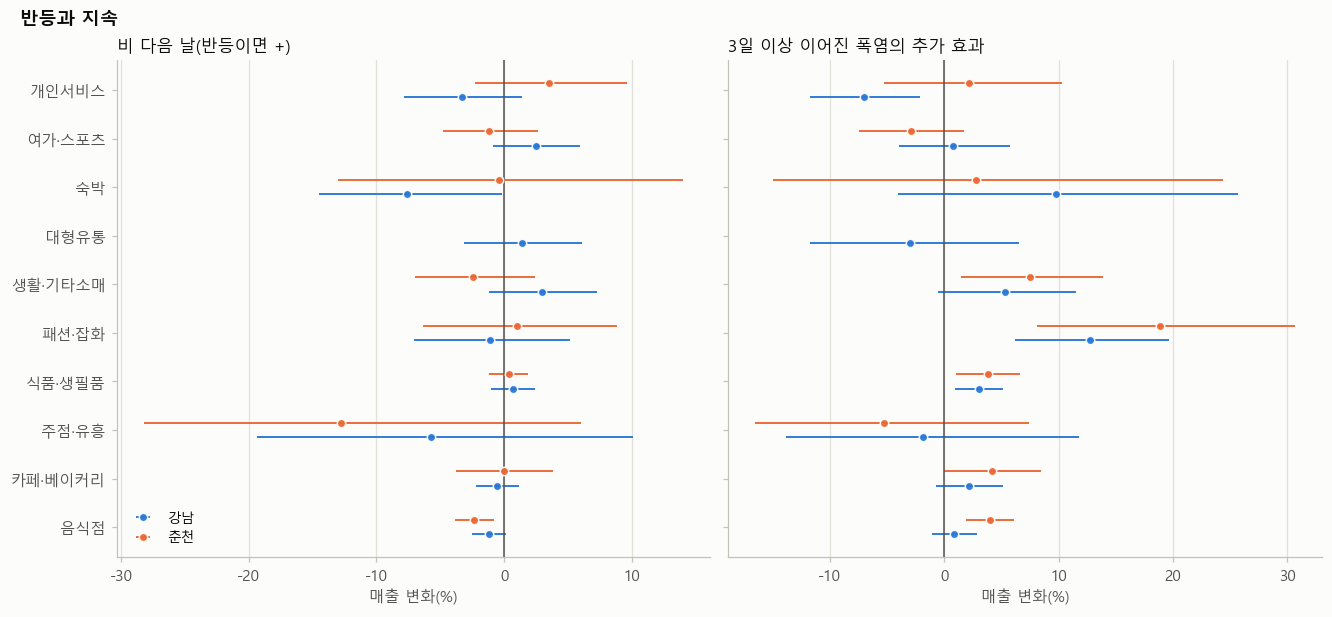

pct   lo   hi
var              region                  
rain_biz10       chuncheon -8.5 -9.6 -7.3
                 gangnam   -5.8 -6.9 -4.6
rain_biz10_lag1  chuncheon -0.9 -1.8  0.1
                 gangnam   -0.3 -1.1  0.5
rain_biz10_lead1 chuncheon -3.3 -4.4 -2.2
                 gangnam    0.6 -0.3  1.5
heat_day         chuncheon  1.4  0.4  2.5
                 gangnam    2.0  1.0  2.9
heat_long        chuncheon  3.7  2.3  5.1
                 gangnam    1.9  0.8  3.1
tropical         chuncheon  1.1  0.0  2.1
                 gangnam   -0.4 -1.5  0.6
tropical_long    gangnam    0.4 -0.4  1.2

In [10]:
d3 = scope[scope.group.isin(FACE_GROUPS)].copy()
d3["heat_long"] = ((d3.w_heat_day == 1) & (d3.w_heat_streak >= 3)).astype(int)
d3["tropical_long"] = ((d3.w_tropical == 1) & (d3.w_tropical_streak >= 3)).astype(int)
pers = run_series(d3, ["region", "industry"], ["heat_day", "heat_long", "tropical", "tropical_long", "rain_biz10", "rain_biz10_lag1", "rain_biz10_lead1"])
pers = pers.merge(prof[["region", "industry", "group"]], on=["region", "industry"])
ppers = pd.concat({v: pool(pers[pers["var"] == v], ["region", "group"]) for v in ["rain_biz10", "rain_biz10_lag1", "rain_biz10_lead1", "heat_day", "heat_long"]}, names=["var", "region", "group"])
ppers.reset_index().to_csv(TAB / "s_persistence_group.csv", index=False, encoding="utf-8-sig")
ppers_r = pd.concat({v: pool(pers[pers["var"] == v], ["region"]) for v in ["rain_biz10", "rain_biz10_lag1", "rain_biz10_lead1", "heat_day", "heat_long", "tropical", "tropical_long"]}, names=["var", "region"])
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharey=True, layout="constrained")
for k, (ax, v) in enumerate(zip(axes, ["rain_biz10_lag1", "heat_long"])):
    forest(ax, ppers.loc[v], FACE_GROUPS, v, legend=(k == 0))
    ax.set_title({"rain_biz10_lag1": "비 다음 날(반등이면 +)", "heat_long": "3일 이상 이어진 폭염의 추가 효과"}[v])
    ax.set_xlabel("매출 변화(%)")
finish(fig, FIG, "s05_persistence", "반등과 지속")
plt.show()
ppers_r[["pct", "lo", "hi"]].round(1)

## 8. 강건성 점검

1. 회귀 결과 vs 단순 편차 비교(시리즈별 비 10mm+ 효과)
2. 소비쿠폰 지급 직후 2주(7/21~8/3, 9/22~10/5)를 빼고 다시 추정
3. 폭염 정의를 체감온도 33℃ 이상(특보 기준값)으로 바꿔서 추정

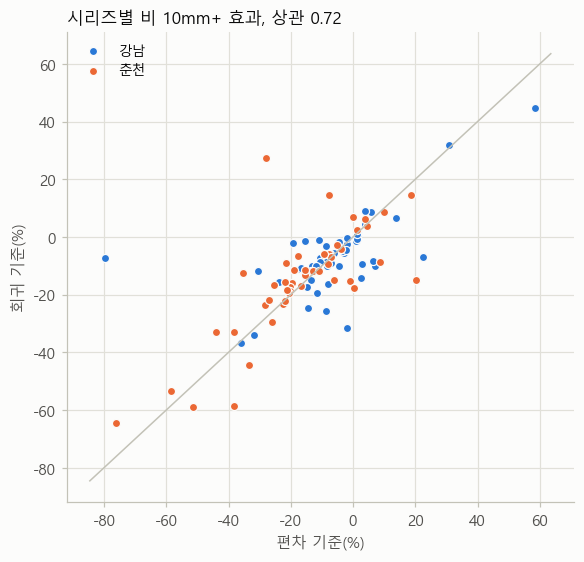

pct                          lo                          hi                       
spec                   기본 쿠폰 직후 2주 제외 폭염=체감 33℃+   기본 쿠폰 직후 2주 제외 폭염=체감 33℃+   기본 쿠폰 직후 2주 제외 폭염=체감 33℃+
var        region                                                                                       
heat_day   chuncheon  2.7         0.6        0.7  1.6        -0.4       -0.3  3.8         1.6        1.7
           gangnam    2.6         3.0        0.9  1.6         2.0       -0.0  3.6         4.0        1.8
rain_biz10 chuncheon -8.7        -7.9       -8.9 -9.8        -9.1      -10.0 -7.5        -6.7       -7.8
           gangnam   -5.7        -6.3       -5.7 -6.9        -7.5       -6.9 -4.6        -5.0       -4.6
tropical   chuncheon  1.7         1.6        2.1  0.5         0.5        0.9  3.0         2.8        3.3
           gangnam   -0.4        -1.8       -0.1 -1.5        -2.8       -1.0  0.6        -0.8        0.8

In [11]:
# 1. 회귀 vs 편차
fd = deviation(scope[scope.group.isin(FACE_GROUPS)], ["region", "industry"], excl=EXCL).merge(w[["region", "date", "rain_biz10", "rn_biz"]], on=["region", "date"])
cdev = contrast(fd, ["region", "industry"], fd.rain_biz10 == 1, fd.rn_biz < 1)
cmp_ = sens[sens["var"] == "rain_biz10"].set_index(["region", "industry"])[["pct"]].join(cdev[["pct"]].rename(columns={"pct": "pct_dev"}), how="inner")
corr = cmp_.corr().iloc[0, 1]
fig, ax = plt.subplots(figsize=(5.2, 5), layout="constrained")
for r in REGIONS:
    x = cmp_.xs(r, level="region")
    ax.scatter(x.pct_dev, x.pct, s=28, color=REGION_COLOR[r], edgecolors=SURFACE, linewidths=0.8, label=REGION_NAME[r])
lim = [min(cmp_.min()) - 5, max(cmp_.max()) + 5]
ax.plot(lim, lim, color=AXIS, lw=1); ax.set_xlabel("편차 기준(%)"); ax.set_ylabel("회귀 기준(%)"); ax.legend()
ax.set_title(f"시리즈별 비 10mm+ 효과, 상관 {corr:.2f}")
finish(fig, FIG, "s06_robust_dev", None)
plt.show()
# 2. 쿠폰 직후 제외 / 3. 폭염 정의 변경
excl2 = scope[~(scope.date.between("2025-07-21", "2025-08-03") | scope.date.between("2025-09-22", "2025-10-05"))]
r2 = run_series(excl2[excl2.group.isin(FACE_GROUPS)], ["region", "industry"], EV + LAGS)
d4 = scope[scope.group.isin(FACE_GROUPS)].copy(); d4["heat_day"] = d4.w_heat_feels33
r3 = run_series(d4, ["region", "industry"], EV + LAGS)
rob = pd.concat({"기본": pool(sens[sens.group.isin(FACE_GROUPS) & sens["var"].isin(["heat_day", "tropical", "rain_biz10"])], ["var", "region"]),
                 "쿠폰 직후 2주 제외": pool(r2[r2["var"].isin(["heat_day", "tropical", "rain_biz10"])], ["var", "region"]),
                 "폭염=체감 33℃+": pool(r3[r3["var"].isin(["heat_day", "tropical", "rain_biz10"])], ["var", "region"])}, names=["spec", "var", "region"])
rob[["pct", "lo", "hi"]].round(1).unstack("spec")

## 9. 요약

지역·업종군·시간대·연령·거주지별 민감도 표는 `outputs/tables/s_*.csv`에 있다. 다음 단계(30)에서 시리즈별 계수를 취약 지수의 '민감도' 축으로 쓴다.

In [12]:
def pool_sales(res, by):
    """매출액 가중 평균(경제적 크기 기준). 통계적 정밀도 가중(pool)과 같이 보고한다."""
    r = res.dropna(subset=["coef", "se"]).copy()
    g = r.groupby(by)
    out = pd.DataFrame({"coef": g.apply(lambda x: np.average(x.coef, weights=x.sales_day), include_groups=False),
                        "se": g.apply(lambda x: np.sqrt(np.sum((x.sales_day / x.sales_day.sum()) ** 2 * x.se ** 2)), include_groups=False)})
    out["pct"] = pct(out.coef); out["lo"] = pct(out.coef - 1.96 * out.se); out["hi"] = pct(out.coef + 1.96 * out.se)
    return out
face_s = sens[sens.group.isin(FACE_GROUPS) & sens["var"].isin(EV + LAGS)]
summ = pd.concat({"정밀도 가중": P_reg[["pct", "lo", "hi"]], "매출 가중": pool_sales(face_s, ["var", "region"])[["pct", "lo", "hi"]]}, axis=1).round(1)
summ.to_csv(TAB / "s_summary.csv", encoding="utf-8-sig")
summ

정밀도 가중           매출 가중            
                              pct   lo   hi   pct    lo    hi
var              region                                      
heat_day         chuncheon    2.7  1.6  3.8   2.6   0.3   4.9
                 gangnam      2.6  1.6  3.6   3.2   1.2   5.3
tropical         chuncheon    1.7  0.5  3.0   2.0  -0.7   4.8
                 gangnam     -0.4 -1.5  0.6  -1.3  -3.3   0.8
rain_biz10       chuncheon   -8.7 -9.8 -7.5 -14.6 -16.6 -12.5
                 gangnam     -5.7 -6.9 -4.6 -11.3 -16.8  -5.4
cold12           chuncheon   -4.6 -5.7 -3.5  -8.7 -11.2  -6.1
rain_biz10_lag1  chuncheon   -0.6 -1.6  0.3  -1.5  -3.3   0.4
                 gangnam     -0.3 -1.1  0.5   0.6  -1.7   3.0
rain_biz10_lead1 chuncheon   -3.6 -4.7 -2.4  -4.8  -6.9  -2.7
                 gangnam      0.4 -0.5  1.4   1.7  -0.9   4.4
heat_day_lag1    chuncheon    2.1  1.0  3.2   1.4  -0.7   3.6
                 gangnam      0.3 -0.4  1.0   0.8  -1.2   2.9